In [1]:
# import required modules 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import cooltools
import bioframe
import cooler

import HMMC


In [2]:
cooler_file = '/gladstone/engelhardt/lab/lchumpitaz/hi-c/mcools/4DNFIXP4QG5B.mcool'

In [3]:
fasta_file='/gladstone/engelhardt/lab/lchumpitaz/hi-c/hg38.fa'

In [4]:
cooler.fileops.list_coolers(cooler_file)

['/resolutions/1000',
 '/resolutions/2000',
 '/resolutions/5000',
 '/resolutions/10000',
 '/resolutions/25000',
 '/resolutions/50000',
 '/resolutions/100000',
 '/resolutions/250000',
 '/resolutions/500000',
 '/resolutions/1000000',
 '/resolutions/2500000',
 '/resolutions/5000000',
 '/resolutions/10000000']

In [5]:
# load cooler, obtain bin table
resolution = 25000
c = cooler.Cooler(cooler_file+'::resolutions/'+str(resolution))
chromsizes = c.chromsizes      
bins = c.bins()[:]

In [6]:
fasta_records = bioframe.load_fasta(fasta_file)
gc_table = bioframe.frac_gc(bins, fasta_records)

In [7]:
regions = HMMC.chrom_regions('hg38', chromsizes)
regions

[('chr1', 0, np.int32(248956422)),
 ('chr2', 0, np.int32(242193529)),
 ('chr3', 0, np.int32(198295559)),
 ('chr4', 0, np.int32(190214555)),
 ('chr5', 0, np.int32(181538259)),
 ('chr6', 0, np.int32(170805979)),
 ('chr7', 0, np.int32(159345973)),
 ('chr8', 0, np.int32(145138636)),
 ('chr9', 0, np.int32(138394717)),
 ('chr10', 0, np.int32(133797422)),
 ('chr11', 0, np.int32(135086622)),
 ('chr12', 0, np.int32(133275309)),
 ('chr13', 0, np.int32(114364328)),
 ('chr14', 0, np.int32(107043718)),
 ('chr15', 0, np.int32(101991189)),
 ('chr16', 0, np.int32(90338345)),
 ('chr17', 0, np.int32(83257441)),
 ('chr18', 0, np.int32(80373285)),
 ('chr19', 0, np.int32(58617616)),
 ('chr20', 0, np.int32(64444167)),
 ('chr21', 0, np.int32(46709983)),
 ('chr22', 0, np.int32(50818468))]

In [8]:
def get_transmaps(c, chrom, regions):
    contact_maps = list()
    for region in regions:
        if region[0]==chrom:
            continue
        contact_maps.append(c.matrix(balance=True).fetch(region[0],chrom))
        
    return np.concatenate(contact_maps, axis=0)

In [9]:
def get_allcontacts(c, chrom, regions):
    contact_maps = list()
    for region in regions:
        contact_maps.append(c.matrix(balance=True).fetch(region[0],chrom))
        
    return np.concatenate(contact_maps, axis=0)

In [10]:
contact_map = c.matrix(balance=True).fetch('chr22','chr19')

In [11]:
contact_map.sum(axis=0)

array([nan, nan, nan, ..., nan, nan, nan], shape=(2345,))

In [12]:
contact_map2 = contact_map.copy()
contact_map2[np.isnan(contact_map)] = 0
mask1 = contact_map2.sum(axis=1) != 0
mask2 = contact_map2.sum(axis=0) != 0
contact_map_masked = contact_map2[:,mask2][mask1]
contact_map_masked = contact_map_masked

In [13]:
def correction(M, iterations = 10):
    W = M.copy()
    for i in range(iterations):
        B0 = W.sum(axis=1)
        B1 = W.sum(axis=0)
        B0[B0==0]=1
        B1[B1==0]=1
        B0 = B0/(B0.mean())
        B1 = B1/(B1.mean())
        outer = np.outer(B0, B1)
        W = W/outer
    
    return W

In [14]:
contact_map_masked = correction(contact_map_masked, 300)

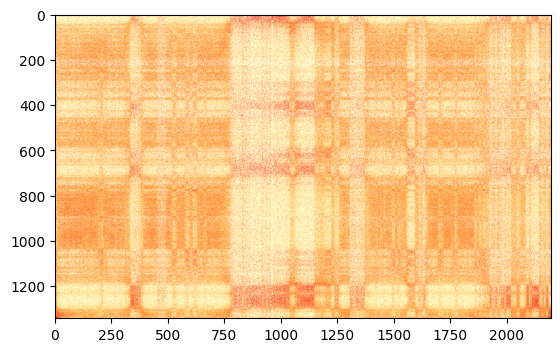

In [15]:
plt.imshow(np.log(contact_map_masked+1e-6), cmap='YlOrRd')

In [16]:
C = np.dot(contact_map_masked.T, contact_map_masked)
C = np.clip(C,np.percentile(C,1), np.percentile(C,99))
C = np.log(C)
C = (C - C.min())
C = C*2/ C.max()
C = C - np.median(C)

(array([ 180834.,  255568.,  406738.,  604784.,  931420., 1232490.,
         863582.,  173154.,   72298.,   97157.]),
 array([-1.0051046, -0.8051046, -0.6051046, -0.4051046, -0.2051046,
        -0.0051046,  0.1948954,  0.3948954,  0.5948954,  0.7948954,
         0.9948954]),
 <BarContainer object of 10 artists>)

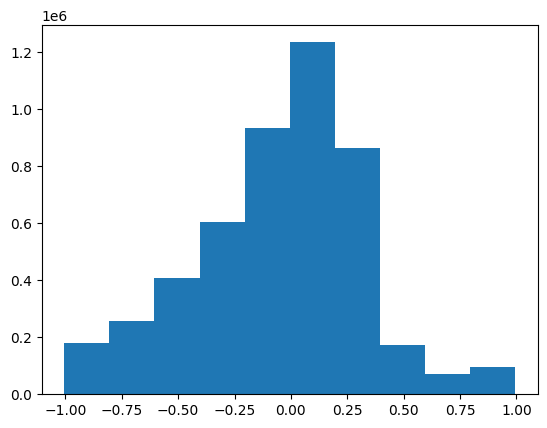

In [17]:
plt.hist(C.reshape(-1))

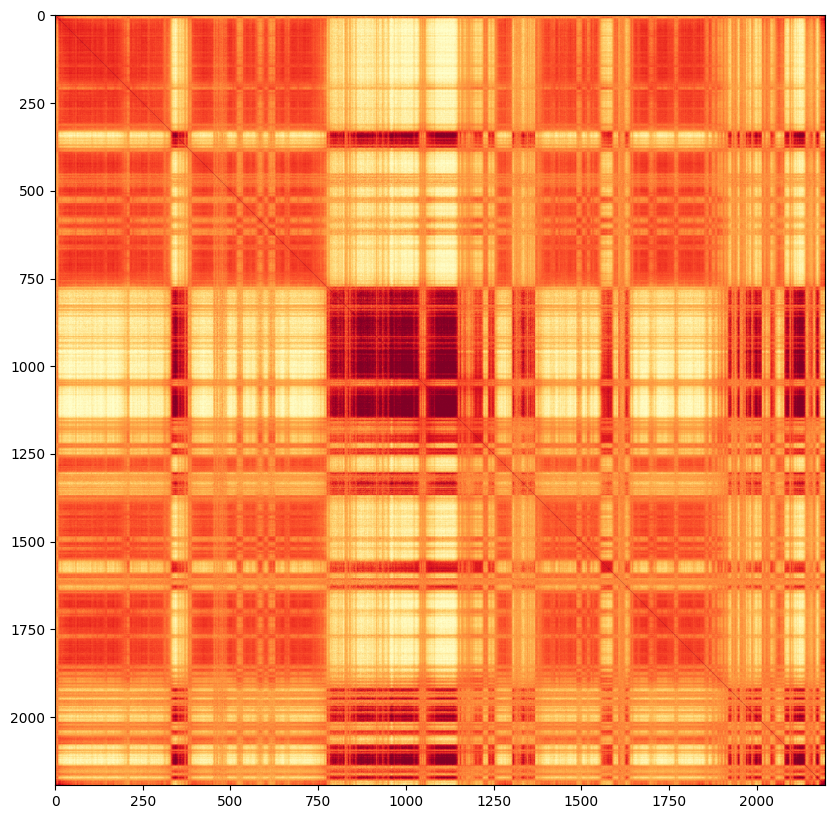

In [18]:
plt.figure(figsize=(10, 10))
plt.imshow(C, cmap='YlOrRd')

In [19]:
U, S, V = np.linalg.svd(C)

In [20]:
np.round(S[:10]/(np.sum(np.abs(S))), 2)

array([0.1 , 0.02, 0.01, 0.01, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

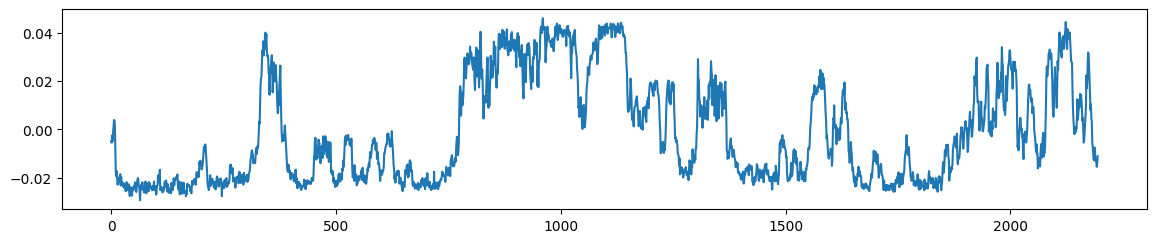

In [21]:
plt.figure(figsize=(14, 2.6))
plt.plot(U[:,0])

In [22]:
mask2 = np.where(U[:,0]>0, True, False)

In [23]:
from hmmlearn import hmm

def _make_transmat(n_states, constrained=False):
    transmat = np.ones((n_states, n_states)) / 10
    np.fill_diagonal(transmat, 0.6)
    transmat /= transmat.sum(axis=1, keepdims=True)
    return transmat

def build_hmm(data, n_components=3, verbose=False):
    model = hmm.GaussianHMM(n_components, params='stmc', init_params='sc', covariance_type="tied", tol=1e-30, n_iter=100)
    model.means_ = np.percentile(data, [20, 50, 80], axis=0)
    
    model.transmat_ = _make_transmat(n_components)
    if verbose:
#         print("means:", model.means_)
        print("transmat:", model.transmat_)
    
    return model



In [24]:
data = -U[:, 0:1]

In [25]:
model = build_hmm(data, verbose=True)
model.fit(data)

transmat: [[0.75  0.125 0.125]
 [0.125 0.75  0.125]
 [0.125 0.125 0.75 ]]


,n_components,3
,covariance_type,'tied'
,min_covar,0.001
,startprob_prior,1.0
,transmat_prior,1.0
,means_prior,0
,means_weight,0
,covars_prior,0.01
,covars_weight,1
,algorithm,'viterbi'
,random_state,None


In [26]:
np.round(model.transmat_,3)

array([[0.97 , 0.03 , 0.   ],
       [0.027, 0.955, 0.019],
       [0.   , 0.007, 0.993]])

In [27]:
prediction = model.predict(data)

In [28]:
x = np.arange(0, len(data))

In [29]:
# plt.scatter(data[:,0], data[:,1], c=prediction)

In [30]:
# X, X_p = model.sample(10000, random_state=1997)
# plt.scatter(X[:,0], X[:,1], c=X_p)

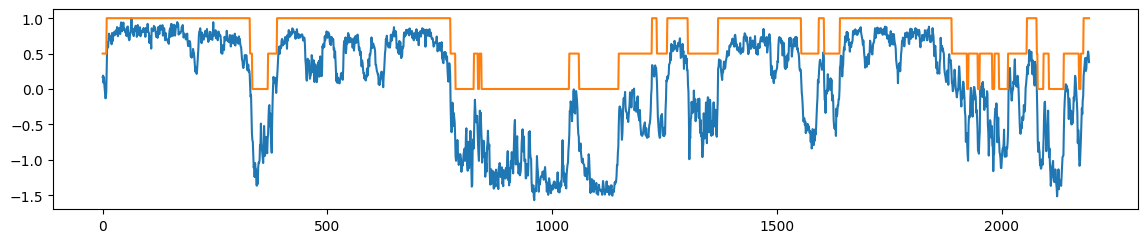

In [31]:
%matplotlib inline
plt.figure(figsize=(14, 2.6))
plt.plot(data[:,0]/(data[:,0].max()))
plt.plot(prediction/2)